# Thermal zoning and preserved quantities

Compare detail levels while preserving the physical building. More zones increase workload and do not automatically improve a stock model.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** notebook environment; no EnergyPlus or weather required.

## Understanding the API in this lesson

Thermal zones subdivide the calculation, while building parts describe physical form. `ZoningSpec(mode=...)` selects whole-building, per-storey or perimeter/core partitioning. The first two are not changes to the measured footprint or floor area. `depth_m` controls perimeter strips in metres.

Use the floor-partition figure to follow one footprint across zoning choices. Then inspect the dependency diagram: logical windows are resolved on physical facade runs and assigned to thermal parents, so more thermal panes do not necessarily mean more physical windows. Apartment zoning is a separate physical-layout model and is covered in its own lesson.

### Figure guide — The same forms under different thermal partitions

![The same forms under different thermal partitions; reference figure from EPSM documentation](../../docs/figures/geometry-zoning.svg)

**How to read this figure.** Read each footprint across the zoning alternatives. Internal coloured regions are calculation zones, not automatically new construction walls. Courtyard edges and exposed parts seed perimeter strips. The shown 4.5 m perimeter depth is a declared example assumption, not a universally calibrated value.

*Source: [EPSM geometry documentation](../../docs/geometry.md); [open the original figure](../../docs/figures/geometry-zoning.svg).*

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Resolve three zoning modes

Per-storey is the default. Perimeter/core uses exposed facade strips; its 4.5 m depth is an explicit modelling assumption.

### Read the code and output

Compare the zone counts only after checking the common area and volume columns. More zones create additional state variables and surface relationships. They can support different questions, but a higher count alone provides no evidence of improved national energy estimates. Retain the chosen depth with each perimeter/core case.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

,mode,zones,floor_area_m2,volume_m3
0,whole_building,1,1800.0,5400.0
1,per_storey,3,1800.0,5400.0
2,perimeter_core,15,1800.0,5400.0


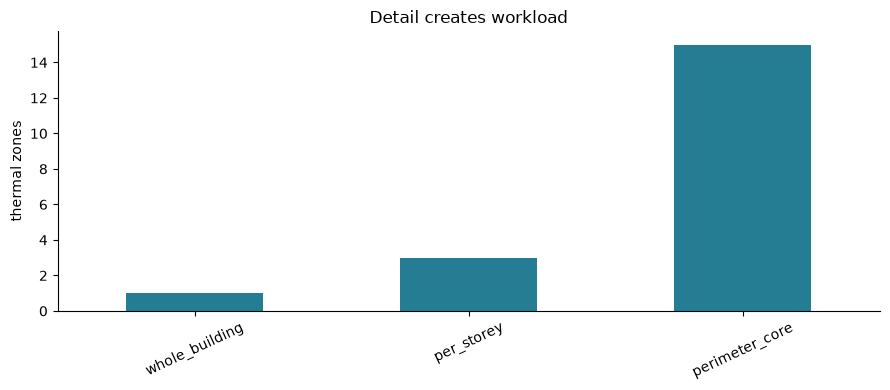

In [2]:
modes = ["whole_building", "per_storey", "perimeter_core"]
variants = {mode: geometry(zoning=ZoningSpec(mode=mode)) for mode in modes}
reports = {mode: geometry_scene(g)[1] for mode,g in variants.items()}
table([{"mode": mode, "zones": len(reports[mode]["zones"]), "floor_area_m2": g.conditioned_floor_area_m2, "volume_m3": g.conditioned_volume_m3} for mode,g in variants.items()])
assert len({g.conditioned_volume_m3 for g in variants.values()}) == 1
bars({mode: len(r["zones"]) for mode,r in reports.items()}, "thermal zones", "Detail creates workload")

## Inspect floor partitions

The chart uses actual emitted horizontal floor surfaces. Virtual zone boundaries must not be interpreted as new material walls.

### Read the code and output

These plots use the generated ground-level floor faces, so their boundaries expose the actual partitioning. Internal lines are not necessarily material walls. The geometry figure includes courtyard and unequal-wing examples beyond this notebook's rectangle; use them to anticipate where exposure-based strips will differ across a diverse stock.

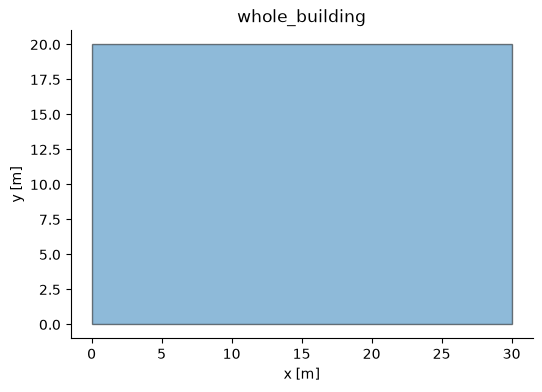

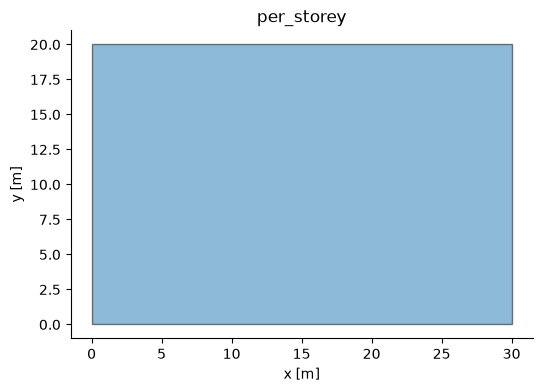

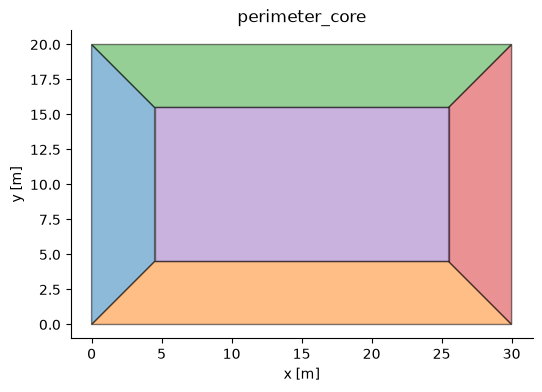

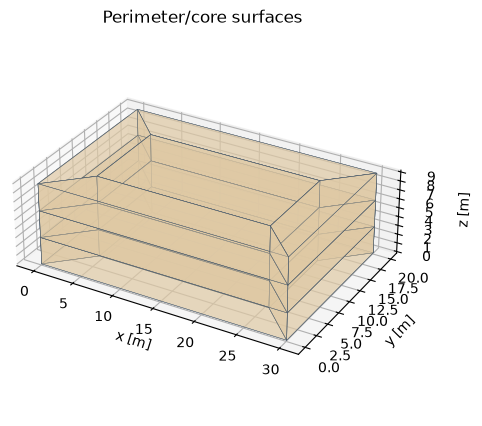

In [3]:
from shapely.geometry import Polygon
plans_by_mode = {}
for mode,g in variants.items():
    model, report = geometry_scene(g)
    floors = [Polygon([(v["vertex_x_coordinate"], v["vertex_y_coordinate"]) for v in s["vertices"]]) for s in model["BuildingSurface:Detailed"].values() if s["surface_type"] == "Floor" and all(abs(v["vertex_z_coordinate"]) < 1e-6 for v in s["vertices"])]
    fig, ax = plt.subplots(figsize=(9, 4))
    for i,p in enumerate(floors): ax.fill(*p.exterior.xy, alpha=.5, edgecolor="black")
    ax.set(title=mode, xlabel="x [m]", ylabel="y [m]", aspect="equal")
    plt.show(); plt.close(fig)
preview(variants["perimeter_core"], "Perimeter/core surfaces")

## Expose the failure policy

Fallback is opt-in and applies to the whole building. Always inspect requested and effective modes before including a case in a comparison of detail levels.

### Read the code and output

`on_failure="per_storey"` permits substitution; it does not force it. This simple example succeeds in the requested mode, as its assertion shows. Always read `effective_mode` and the substitution flag in a real batch. Exclude substituted cases from a comparison that claims to measure the failed zoning method.

In [4]:
policy = ZoningSpec(mode="perimeter_core", depth_m=4.5, on_failure="per_storey")
_, report = geometry_scene(geometry(zoning=policy))
table(report["zoning"])
assert report["zoning"]["effective_mode"] == "perimeter_core"

,field,value
0,requested_mode,perimeter_core
1,effective_mode,perimeter_core
2,on_failure,per_storey
3,substituted,False


## Interpretation and next experiment

First establish invariant area, volume and prescribed loads. Use the results notebooks for matched energy comparisons; a zone-count chart alone says nothing about accuracy.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.